# CTU-13 Scenario 42 — Botnet C2 Detection Pipeline
## DBSCAN Anomaly Detection, Statistical Beaconing Detection & Hybrid Synthesis
### SIH 2026 - Problem Statement 26145: AI-Based Detection of Cyber Threats in Unidirectional IP Traffic

---

### Executive Overview & Detection Philosophy
This notebook implements the first machine learning and behavioral detection engine for the SIH PS 26145 project, dedicated to detecting **Botnet Command & Control (C2) and Periodic Beaconing** in network flow traffic.

In enterprise and perimeter networks, Botnet C2 channels exhibit subtle, persistent behavioral signatures that traditional static signatures fail to catch:
1. **Low-and-Slow Beaconing**: Periodic heartbeat polls to C2 servers designed to evade rate-based alarms.
2. **High-Fanout Fast-Flux / P2P Coordination**: Compromised hosts querying multiple distributed endpoints.
3. **Manifold & Behavioral Outliers**: Micro-bursts, persistent session re-connections, and anomalous flow structures.

To achieve robust, real-time detection without label leakage, we build and evaluate a **tripartite detection framework**:
- **Detector 1: Statistical Beaconing Detector**: Ranks causal timing regularity (`IAT_Regularity_Causal`), connection frequency (`Src_Flows_60s`, `Src_Flows_300s`, `Src_Flows_BeforeOrAtT`), fan-out diversity (`DstFanoutRatio_Causal`), and endpoint repeat patterns against a clean normal baseline.
- **Detector 2: DBSCAN Anomaly Detector**: Unsupervised density-based spatial clustering fitted strictly on normal network traffic in PCA-reduced space, equipped with an out-of-sample nearest core sample distance boundary.
- **Detector 3: Hybrid Fusion Detector**: Synthesizes statistical timing suspicion with geometric manifold outlier distance to achieve balanced precision and recall.

---

### Core Temporal Causality Rule
To guarantee valid evaluation for real-time streaming deployment:
- **Chronological Split**: The dataset is ordered strictly by `StartTime`. The **first 70%** constitutes the historical Training Period; the **remaining 30%** constitutes the unseen Testing Period. No random shuffling is applied.
- **Normal Training Baseline Only**: All statistical baselines, imputation values, scalers, PCA projections, DBSCAN clusters, and decision thresholds are learned **exclusively from clean Normal flows (`BinaryLabel == 0`) within the historical Training Period**.
- **Zero Label & Future Leakage**: Ground-truth labels are never used as model inputs. The testing period remains completely unseen during calibration.

### 1. Import Libraries & Define Mathematical Engines
Import scientific, visualization, and helper libraries. Define exact PCA, fast DBSCAN via `scipy.spatial.cKDTree`, and vectorized evaluation metric routines.

In [1]:
import os
import sys
import gc
import json
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import cKDTree
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
if hasattr(sys.stdout, 'reconfigure'):
    try:
        sys.stdout.reconfigure(encoding='utf-8')
    except Exception:
        pass

# Display configurations
pd.set_option('display.max_columns', 35)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

print(f"NumPy version:  {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# =====================================================================
# 1. Custom PCA Implementation via Singular Value Decomposition (SVD)
# =====================================================================
class CustomPCA:
    """
    Principal Component Analysis via SVD.
    Fitted strictly on normal baseline to avoid distribution leakage.
    """
    def __init__(self, n_components=None, random_state=42):
        self.n_components = n_components
        self.random_state = random_state
        self.components_ = None
        self.explained_variance_ = None
        self.explained_variance_ratio_ = None
        self.mean_ = None
        self.n_components_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        n_samples, n_features = X.shape
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_
        
        # SVD of centered matrix
        U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
        
        explained_variance = (S ** 2) / (n_samples - 1)
        total_var = np.sum(explained_variance)
        explained_variance_ratio = explained_variance / total_var
        
        if self.n_components is None:
            n_comp = n_features
        elif isinstance(self.n_components, (int, np.integer)):
            n_comp = min(int(self.n_components), n_features)
        elif isinstance(self.n_components, float) and 0.0 < self.n_components < 1.0:
            cum_var = np.cumsum(explained_variance_ratio)
            n_comp = int(np.argmax(cum_var >= self.n_components) + 1)
        else:
            n_comp = n_features
            
        self.n_components_ = n_comp
        self.components_ = Vt[:n_comp]
        self.explained_variance_ = explained_variance[:n_comp]
        self.explained_variance_ratio_ = explained_variance_ratio[:n_comp]
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=np.float64)
        X_centered = X - self.mean_
        return np.dot(X_centered, self.components_.T)

    def fit_transform(self, X):
        return self.fit(X).transform(X)

# =====================================================================
# 2. Fast DBSCAN via cKDTree with Out-of-Sample Core Distance Prediction
# =====================================================================
class FastDBSCAN:
    """
    Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
    Fitted on normal training baseline; provides out-of-sample anomaly scoring
    via nearest core sample Euclidean distance.
    """
    def __init__(self, eps=0.5, min_samples=20):
        self.eps = eps
        self.min_samples = min_samples
        self.labels_ = None
        self.core_sample_indices_ = None
        self.components_ = None
        self.tree_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        n_samples = X.shape[0]
        self.tree_ = cKDTree(X)
        
        # Query epsilon-neighborhood for all training points
        neighbors = self.tree_.query_ball_point(X, r=self.eps)
        
        # Identify core samples (having >= min_samples within eps)
        is_core = np.array([len(nbrs) >= self.min_samples for nbrs in neighbors], dtype=bool)
        self.core_sample_indices_ = np.where(is_core)[0]
        self.components_ = X[self.core_sample_indices_]
        
        labels = np.full(n_samples, -1, dtype=int)
        cluster_id = 0
        
        for i in range(n_samples):
            if labels[i] != -1 or not is_core[i]:
                continue
            
            labels[i] = cluster_id
            queue = list(neighbors[i])
            visited = set(queue)
            visited.add(i)
            
            head = 0
            while head < len(queue):
                neighbor_idx = queue[head]
                head += 1
                
                if labels[neighbor_idx] == -1:
                    labels[neighbor_idx] = cluster_id
                
                if is_core[neighbor_idx]:
                    for next_nbr in neighbors[neighbor_idx]:
                        if next_nbr not in visited:
                            visited.add(next_nbr)
                            queue.append(next_nbr)
            
            cluster_id += 1
            
        self.labels_ = labels
        return self

    def predict_distance_and_anomaly(self, X):
        """
        Calculates distance to the nearest core sample.
        If distance > eps -> Anomaly = 1, else 0.
        """
        X = np.asarray(X, dtype=np.float64)
        if len(self.core_sample_indices_) == 0:
            return np.full(len(X), np.inf), np.ones(len(X), dtype=int)
            
        core_tree = cKDTree(self.components_)
        distances, _ = core_tree.query(X, k=1)
        anomalies = (distances > self.eps).astype(int)
        return distances, anomalies

# =====================================================================
# 3. Vectorized Classification and Curve Metrics
# =====================================================================
def compute_confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return np.array([[tn, fp], [fn, tp]])

def compute_classification_metrics(y_true, y_pred, y_prob=None):
    cm = compute_confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    total = tn + fp + fn + tp
    acc = (tp + tn) / total if total > 0 else 0.0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    tpr = rec
    
    roc_auc = np.nan
    pr_auc = np.nan
    
    if y_prob is not None:
        y_prob = np.asarray(y_prob, dtype=np.float64)
        y_true = np.asarray(y_true, dtype=int)
        pos_scores = y_prob[y_true == 1]
        neg_scores = y_prob[y_true == 0]
        n_pos = len(pos_scores)
        n_neg = len(neg_scores)
        
        if n_pos > 0 and n_neg > 0:
            order = np.argsort(y_prob)
            ranks = np.empty_like(order, dtype=float)
            ranks[order] = np.arange(1, len(y_prob) + 1)
            
            unique_vals, inverse, counts = np.unique(y_prob, return_inverse=True, return_counts=True)
            if len(unique_vals) < len(y_prob):
                tie_ranks = np.bincount(inverse, weights=ranks) / counts
                ranks = tie_ranks[inverse]
                
            rank_sum_pos = np.sum(ranks[y_true == 1])
            roc_auc = (rank_sum_pos - n_pos * (n_pos + 1) / 2.0) / (n_pos * n_neg)
            
            sort_idx = np.argsort(-y_prob)
            y_sorted = y_true[sort_idx]
            cum_tp = np.cumsum(y_sorted == 1)
            cum_fp = np.cumsum(y_sorted == 0)
            
            precision_arr = cum_tp / (cum_tp + cum_fp)
            recall_arr = cum_tp / n_pos
            
            rec_full = np.concatenate(([0.0], recall_arr))
            prec_full = np.concatenate(([1.0], precision_arr))
            if hasattr(np, 'trapezoid'):
                pr_auc = float(np.trapezoid(prec_full, rec_full))
            else:
                pr_auc = float(np.sum(np.diff(rec_full) * (prec_full[1:] + prec_full[:-1]) / 2.0))

    return {
        'Accuracy': float(acc),
        'Precision': float(prec),
        'Recall': float(rec),
        'F1': float(f1),
        'FPR': float(fpr),
        'TPR': float(tpr),
        'TP': int(tp),
        'FP': int(fp),
        'TN': int(tn),
        'FN': int(fn),
        'ROC_AUC': float(roc_auc) if not np.isnan(roc_auc) else None,
        'PR_AUC': float(pr_auc) if not np.isnan(pr_auc) else None
    }

NumPy version:  2.5.3
Pandas version: 3.0.6


### 2. Load Datasets & Verify Strict Alignment
Load full online dataset (`ctu13_c2_online_features.csv`), online model features (`ctu13_c2_online_model_features.csv`), and the audit table (`ctu13_online_feature_audit.csv`).
Verify row counts, timestamps, and target labels.

In [2]:
# Resolve project root dynamically
if Path('data/processed').exists():
    project_root = Path.cwd().resolve()
elif Path('../data/processed').exists():
    project_root = Path.cwd().parent.resolve()
else:
    project_root = Path.cwd().resolve()

data_dir = project_root / 'data' / 'processed' / 'CTU13'
models_dir = project_root / 'models' / 'c2'
eval_dir = project_root / 'evaluation'

models_dir.mkdir(parents=True, exist_ok=True)
eval_dir.mkdir(parents=True, exist_ok=True)

full_csv = data_dir / 'ctu13_c2_online_features.csv'
model_csv = data_dir / 'ctu13_c2_online_model_features.csv'
audit_csv = data_dir / 'ctu13_online_feature_audit.csv'

df_full = pd.read_csv(full_csv)
df_model = pd.read_csv(model_csv)
df_audit = pd.read_csv(audit_csv)

df_full['StartTime'] = pd.to_datetime(df_full['StartTime'], errors='coerce', utc=True)

# Strict Alignment Assertions
assert len(df_full) == len(df_model), f"Row count mismatch: {len(df_full)} vs {len(df_model)}"
assert (df_full['BinaryLabel'] == df_model['BinaryLabel']).all(), "BinaryLabel values do not match exactly across datasets."
assert df_full['StartTime'].is_monotonic_increasing, "Full dataset is not strictly chronologically sorted."

C2_ONLINE_FEATURE_COLUMNS = [c for c in df_model.columns if c != 'BinaryLabel']

print(f"Loaded Full Dataset:        {full_csv.name} ({len(df_full):,} rows, {len(df_full.columns)} cols)")
print(f"Loaded Model Dataset:       {model_csv.name} ({len(df_model):,} rows, {len(df_model.columns)} cols)")
print(f"Loaded Feature Audit:       {audit_csv.name} ({len(df_audit):,} audited features)")
print(f"Total Online C2 Features:   {len(C2_ONLINE_FEATURE_COLUMNS)}")
print(f"Target BinaryLabel Classes: 1 = Botnet ({(df_model['BinaryLabel']==1).sum():,}), 0 = Normal ({(df_model['BinaryLabel']==0).sum():,})")

Loaded Full Dataset:        ctu13_c2_online_features.csv (71,219 rows, 58 cols)
Loaded Model Dataset:       ctu13_c2_online_model_features.csv (71,219 rows, 47 cols)
Loaded Feature Audit:       ctu13_online_feature_audit.csv (45 audited features)
Total Online C2 Features:   46
Target BinaryLabel Classes: 1 = Botnet (40,961), 0 = Normal (30,258)


### 3. Chronological Train / Test Split
Partition dataset chronologically into **70% Training** and **30% Testing** without random shuffling.

In [3]:
split_idx = int(0.70 * len(df_full))

train_full = df_full.iloc[:split_idx].copy()
test_full = df_full.iloc[split_idx:].copy()

train_model = df_model.iloc[:split_idx].copy()
test_model = df_model.iloc[split_idx:].copy()

y_train = train_model['BinaryLabel'].values
y_test = test_model['BinaryLabel'].values

print("--- Chronological Split Overview ---")
print(f"Training Partition (70%): {len(train_model):,} flows")
print(f"  Start Time: {train_full['StartTime'].min()} | End Time: {train_full['StartTime'].max()}")
print(f"  Botnet Flows: {(y_train == 1).sum():,} ({((y_train == 1).sum()/len(y_train))*100:.2f}%)")
print(f"  Normal Flows: {(y_train == 0).sum():,} ({((y_train == 0).sum()/len(y_train))*100:.2f}%)")

print(f"\nTesting Partition (30%):  {len(test_model):,} flows")
print(f"  Start Time: {test_full['StartTime'].min()} | End Time: {test_full['StartTime'].max()}")
print(f"  Botnet Flows: {(y_test == 1).sum():,} ({((y_test == 1).sum()/len(y_test))*100:.2f}%)")
print(f"  Normal Flows: {(y_test == 0).sum():,} ({((y_test == 0).sum()/len(y_test))*100:.2f}%)")

--- Chronological Split Overview ---
Training Partition (70%): 49,853 flows
  Start Time: 2011-08-10 09:46:53.160043+00:00 | End Time: 2011-08-10 13:52:15.347006+00:00
  Botnet Flows: 28,611 (57.39%)
  Normal Flows: 21,242 (42.61%)

Testing Partition (30%):  21,366 flows
  Start Time: 2011-08-10 13:52:16.207398+00:00 | End Time: 2011-08-10 15:54:07.198435+00:00
  Botnet Flows: 12,350 (57.80%)
  Normal Flows: 9,016 (42.20%)


### 4. Define Normal Training Baseline
For unsupervised anomaly detection and behavioral baseline scoring, extract only clean **Normal flows (`BinaryLabel == 0`) from the Training Partition**.
> **Zero-Leakage Guarantee**: Labels are used exclusively to define the clean training baseline. They are never provided as model input features, and test labels are never inspected during fitting.

In [4]:
normal_mask_train = (y_train == 0)
X_train_normal = train_model.loc[normal_mask_train, C2_ONLINE_FEATURE_COLUMNS].copy()

print(f"Normal Training Baseline Size: {len(X_train_normal):,} flows")
print(f"Feature count: {len(C2_ONLINE_FEATURE_COLUMNS)}")
assert X_train_normal.isnull().sum().sum() == 0, "Null values detected in Normal training baseline."
assert test_model[C2_ONLINE_FEATURE_COLUMNS].isnull().sum().sum() == 0, "Null values detected in test feature set."
print("✅ Baseline features fully non-null and temporally verified.")

Normal Training Baseline Size: 21,242 flows
Feature count: 46
✅ Baseline features fully non-null and temporally verified.


### 5. Feature Scaling (StandardScaler)
Fit `StandardScaler` **strictly on the Normal Training Baseline**.
Distance-based algorithms such as PCA and DBSCAN are sensitive to feature variances; scaling ensures equal geometric weighting across packet sizes, rates, and timing metrics.

In [5]:
scaler = StandardScaler()
X_train_normal_scaled = scaler.fit_transform(X_train_normal)

# Transform training set and unseen test set using training-derived scaler
X_train_all_scaled = scaler.transform(train_model[C2_ONLINE_FEATURE_COLUMNS])
X_test_scaled = scaler.transform(test_model[C2_ONLINE_FEATURE_COLUMNS])

print("StandardScaler successfully fitted on Normal Training Baseline.")
print(f"Feature Means (Train Normal): {scaler.mean_[:5]} ...")
print(f"Feature Scales (Train Normal): {scaler.scale_[:5]} ...")

StandardScaler successfully fitted on Normal Training Baseline.
Feature Means (Train Normal): [   31.2478454      0.             0.            26.72215422
 21580.81908483] ...
Feature Scales (Train Normal): [2.14170831e+02 1.00000000e+00 1.00000000e+00 3.08410366e+02
 3.14123786e+05] ...


### 6. PCA Dimensionality Reduction
Fit `CustomPCA` **strictly on the Normal Training Baseline**.
We target **95% explained variance** capped at **maximum 15 components** to eliminate multicollinearity and avoid the curse of dimensionality in DBSCAN Euclidean distance computation.

Original Feature Count: 46
Components for >=95% variance: 20
Selected PCA Components (Capped at 15): 15
Cumulative Explained Variance with 15 components: 0.8950


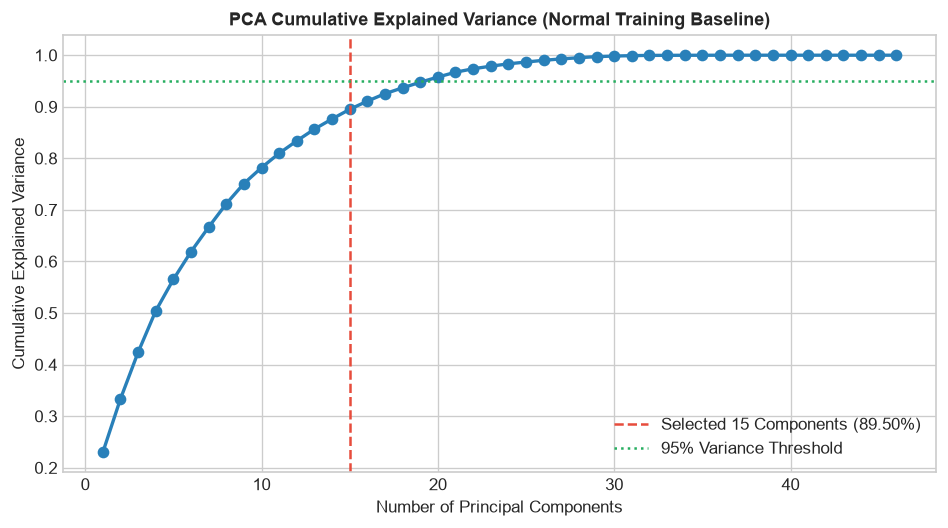

In [6]:
pca_pre = CustomPCA().fit(X_train_normal_scaled)
cum_var = np.cumsum(pca_pre.explained_variance_ratio_)
k_95 = int(np.argmax(cum_var >= 0.95) + 1)
n_components = min(k_95, 15)

print(f"Original Feature Count: {len(C2_ONLINE_FEATURE_COLUMNS)}")
print(f"Components for >=95% variance: {k_95}")
print(f"Selected PCA Components (Capped at 15): {n_components}")
print(f"Cumulative Explained Variance with {n_components} components: {cum_var[n_components-1]:.4f}")

pca = CustomPCA(n_components=n_components, random_state=42)
X_train_normal_pca = pca.fit_transform(X_train_normal_scaled)
X_train_all_pca = pca.transform(X_train_all_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Plot PCA Explained Variance
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', color='#2980b9', lw=2)
plt.axvline(n_components, color='#e74c3c', linestyle='--', label=f'Selected {n_components} Components ({cum_var[n_components-1]:.2%})')
plt.axhline(0.95, color='#27ae60', linestyle=':', label='95% Variance Threshold')
plt.title("PCA Cumulative Explained Variance (Normal Training Baseline)", fontsize=11, fontweight='bold')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

### 7. DBSCAN Parameter Calibration (k-Distance Graph)
Set `min_samples = 20`. Calibrate $\epsilon$ by computing the 20th-nearest-neighbor Euclidean distance curve over the Normal Training Baseline.

Sampled 20,000 normal training flows for DBSCAN fitting (random_state=42).


k-Distance Statistics (k=20):
 - Min:    0.0376
 - Median: 0.5533
 - 90th:   1.6304
 - 95th:   2.2944 (Selected Calibrated Epsilon)
 - 99th:   7.5425
 - Max:    105.9626


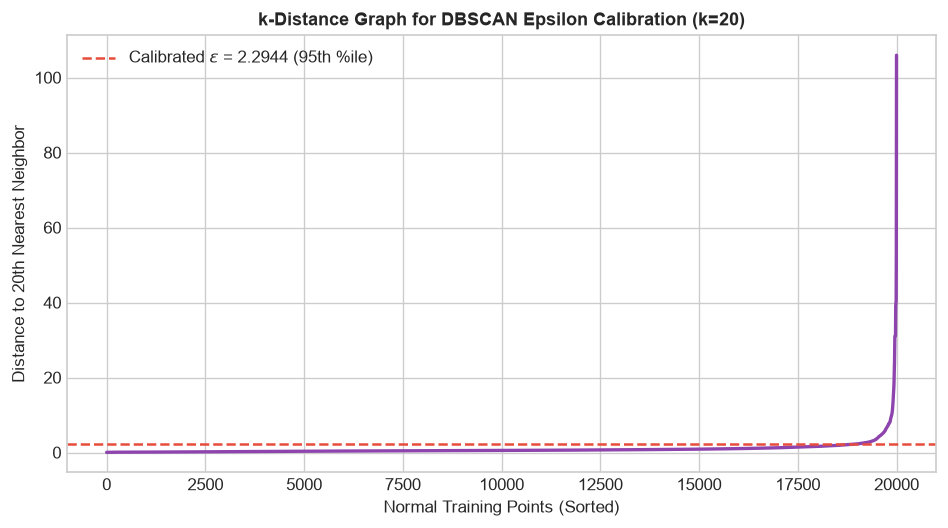

In [7]:
# Deterministic sample of up to 20,000 Normal flows for DBSCAN memory efficiency
if len(X_train_normal_pca) > 20000:
    np.random.seed(42)
    sample_indices = np.random.choice(len(X_train_normal_pca), size=20000, replace=False)
    X_dbscan_train = X_train_normal_pca[sample_indices]
    print(f"Sampled {len(X_dbscan_train):,} normal training flows for DBSCAN fitting (random_state=42).")
else:
    X_dbscan_train = X_train_normal_pca
    print(f"Using full normal training baseline of {len(X_dbscan_train):,} flows.")

min_samples = 20
k = min_samples

tree_kdist = cKDTree(X_dbscan_train)
distances, _ = tree_kdist.query(X_dbscan_train, k=k)
k_distances = distances[:, -1]

eps_90 = float(np.percentile(k_distances, 90))
eps_95 = float(np.percentile(k_distances, 95))
eps_99 = float(np.percentile(k_distances, 99))
calibrated_eps = eps_95

print(f"k-Distance Statistics (k={k}):")
print(f" - Min:    {k_distances.min():.4f}")
print(f" - Median: {np.median(k_distances):.4f}")
print(f" - 90th:   {eps_90:.4f}")
print(f" - 95th:   {eps_95:.4f} (Selected Calibrated Epsilon)")
print(f" - 99th:   {eps_99:.4f}")
print(f" - Max:    {k_distances.max():.4f}")

# Plot k-distance curve
plt.figure(figsize=(8, 4.5))
plt.plot(np.sort(k_distances), color='#8e44ad', lw=2)
plt.axhline(calibrated_eps, color='#e74c3c', linestyle='--', label=f'Calibrated $\\epsilon$ = {calibrated_eps:.4f} (95th %ile)')
plt.title(f"k-Distance Graph for DBSCAN Epsilon Calibration (k={k})", fontsize=11, fontweight='bold')
plt.xlabel("Normal Training Points (Sorted)")
plt.ylabel(f"Distance to {k}th Nearest Neighbor")
plt.legend()
plt.tight_layout()
plt.show()

### 8. Train DBSCAN & Out-of-Sample Anomaly Rule
Fit `FastDBSCAN` on the calibrated Normal baseline.
Implement the **out-of-sample anomaly scoring rule**:
$$\text{DBSCAN\_Distance}(x) = \min_{c \in \text{CoreSamples}} \|x - c\|_2$$
$$\text{DBSCAN\_Anomaly}(x) = \mathbb{I}(\text{DBSCAN\_Distance}(x) > \epsilon)$$

In [8]:
dbscan = FastDBSCAN(eps=calibrated_eps, min_samples=min_samples)
dbscan.fit(X_dbscan_train)

n_clusters = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
n_noise = (dbscan.labels_ == -1).sum()
pct_noise = (n_noise / len(dbscan.labels_)) * 100

print("--- DBSCAN Training Summary (Normal Baseline) ---")
print(f"Clusters Discovered: {n_clusters}")
print(f"Noise Points:        {n_noise:,} ({pct_noise:.2f}%)")
print(f"Core Samples Count:  {len(dbscan.core_sample_indices_):,} / {len(X_dbscan_train):,}")

# Score Normal Training Baseline & Chronological Test Partition
train_normal_dist, train_normal_dbscan_anom = dbscan.predict_distance_and_anomaly(X_train_normal_pca)
test_dist, dbscan_test_anomaly = dbscan.predict_distance_and_anomaly(X_test_pca)

print(f"\nChronological Test Out-of-Sample DBSCAN Scoring:")
print(f" - Test Flows Flagged as Anomalies: {dbscan_test_anomaly.sum():,} / {len(dbscan_test_anomaly):,} ({dbscan_test_anomaly.mean()*100:.2f}%)")
print(f" - Test Distance Range: {test_dist.min():.4f} to {test_dist.max():.4f} (median: {np.median(test_dist):.4f})")

--- DBSCAN Training Summary (Normal Baseline) ---
Clusters Discovered: 5
Noise Points:        631 (3.16%)
Core Samples Count:  19,000 / 20,000



Chronological Test Out-of-Sample DBSCAN Scoring:
 - Test Flows Flagged as Anomalies: 15,118 / 21,366 (70.76%)
 - Test Distance Range: 0.0402 to 296.3818 (median: 47.5484)


### 9. Statistical C2 Beaconing Detector
Construct a transparent, rank-based behavioral scoring engine based on:
1. `Src_Flows_60s` & `Src_Flows_300s` (Burst & sustained host flow generation).
2. `Src_Flows_BeforeOrAtT` (Cumulative source activity).
3. `DstFanoutRatio_Causal` (Destination fan-out / search behavior).
4. `IAT_Regularity_Causal` (Timing regularity index).
5. `RepeatRatio_SrcDst_Causal` (Source-destination repeat ratio).

Features are mapped to empirical percentiles against the **Normal Training Baseline**:
$$\text{BeaconingScore}(x) = \frac{1}{M} \sum_{m=1}^M \hat{F}_{\text{TrainNormal}, m}(x_m)$$

In [9]:
beaconing_features = [
    'Src_Flows_60s',
    'Src_Flows_300s',
    'Src_Flows_BeforeOrAtT',
    'DstFanoutRatio_Causal',
    'IAT_Regularity_Causal',
    'RepeatRatio_SrcDst_Causal'
]

# Build empirical CDF lookup arrays from Normal Training Baseline
train_normal_vals = {f: np.sort(X_train_normal[f].values) for f in beaconing_features}

def compute_beaconing_score(df_features):
    n = len(df_features)
    scores = np.zeros(n, dtype=float)
    for f in beaconing_features:
        ref_arr = train_normal_vals[f]
        pos = np.searchsorted(ref_arr, df_features[f].values, side='right')
        scores += pos / len(ref_arr)
    return scores / len(beaconing_features)

train_normal_beacon_score = compute_beaconing_score(X_train_normal)
test_beacon_score = compute_beaconing_score(test_model[C2_ONLINE_FEATURE_COLUMNS])

# Calibrate Operating Thresholds on Normal Training Baseline
th_1pct = float(np.percentile(train_normal_beacon_score, 99))
th_5pct = float(np.percentile(train_normal_beacon_score, 95))
th_10pct = float(np.percentile(train_normal_beacon_score, 90))

default_beacon_threshold = th_5pct
stat_test_anomaly = (test_beacon_score >= default_beacon_threshold).astype(int)

print("--- Statistical Beaconing Calibration (Normal Training Baseline) ---")
print(f" 1% FPR Operating Point Threshold:  {th_1pct:.4f} (Actual Train-Normal FPR: {(train_normal_beacon_score >= th_1pct).mean()*100:.2f}%)")
print(f" 5% FPR Operating Point (Default):  {th_5pct:.4f} (Actual Train-Normal FPR: {(train_normal_beacon_score >= th_5pct).mean()*100:.2f}%)")
print(f" 10% FPR Operating Point Threshold: {th_10pct:.4f} (Actual Train-Normal FPR: {(train_normal_beacon_score >= th_10pct).mean()*100:.2f}%)")
print(f"\nChronological Test Statistical Anomaly Detections: {stat_test_anomaly.sum():,} / {len(stat_test_anomaly):,} ({stat_test_anomaly.mean()*100:.2f}%)")

--- Statistical Beaconing Calibration (Normal Training Baseline) ---
 1% FPR Operating Point Threshold:  0.7102 (Actual Train-Normal FPR: 1.00%)
 5% FPR Operating Point (Default):  0.6796 (Actual Train-Normal FPR: 5.00%)
 10% FPR Operating Point Threshold: 0.6497 (Actual Train-Normal FPR: 10.00%)

Chronological Test Statistical Anomaly Detections: 6,712 / 21,366 (31.41%)


### 10. Hybrid Fusion Detector Architecture
Fuse normalized DBSCAN distance and Statistical Beaconing Score:
$$\text{HybridScore}(x) = 0.5 \cdot \text{DBSCAN\_Dist\_Norm}(x) + 0.5 \cdot \text{BeaconingScore}(x)$$
Threshold is calibrated strictly at the 5% FPR operating point of the **Normal Training Baseline**.

In [10]:
# Normalize DBSCAN distance via empirical CDF of Normal Training Baseline
sorted_normal_dist = np.sort(train_normal_dist)

def normalize_dbscan_distance(dist_arr):
    pos = np.searchsorted(sorted_normal_dist, dist_arr, side='right')
    return pos / len(sorted_normal_dist)

train_normal_dbscan_norm = normalize_dbscan_distance(train_normal_dist)
test_dbscan_norm = normalize_dbscan_distance(test_dist)

train_normal_hybrid_score = 0.5 * train_normal_dbscan_norm + 0.5 * train_normal_beacon_score
test_hybrid_score = 0.5 * test_dbscan_norm + 0.5 * test_beacon_score

default_hybrid_threshold = float(np.percentile(train_normal_hybrid_score, 95))
hybrid_test_anomaly = (test_hybrid_score >= default_hybrid_threshold).astype(int)

# Synthesize Explainable Detection Reasons (without referencing ground truth)
test_detection_reasons = []
for d_anom, b_anom in zip(dbscan_test_anomaly, stat_test_anomaly):
    if d_anom == 1 and b_anom == 1:
        test_detection_reasons.append("DBSCAN + C2 beaconing")
    elif d_anom == 1:
        test_detection_reasons.append("DBSCAN anomaly")
    elif b_anom == 1:
        test_detection_reasons.append("C2 beaconing behavior")
    else:
        test_detection_reasons.append("No anomaly")

print(f"Hybrid Score 5% FPR Threshold (Normal Training Baseline): {default_hybrid_threshold:.4f}")
print(f"Chronological Test Hybrid Anomaly Detections: {hybrid_test_anomaly.sum():,} / {len(hybrid_test_anomaly):,} ({hybrid_test_anomaly.mean()*100:.2f}%)")
print(f"\nDetection Reasons Breakdown on Test Set:")
print(pd.Series(test_detection_reasons).value_counts())

Hybrid Score 5% FPR Threshold (Normal Training Baseline): 0.7891
Chronological Test Hybrid Anomaly Detections: 11,003 / 21,366 (51.50%)

Detection Reasons Breakdown on Test Set:
DBSCAN anomaly           8464
DBSCAN + C2 beaconing    6654
No anomaly               6190
C2 beaconing behavior      58
Name: count, dtype: int64


### 11. Performance Evaluation on Unseen Test Partition
Evaluate all three detectors against ground truth `BinaryLabel` (1 = Botnet, 0 = Normal) on the **last 30% chronological flows**.

In [11]:
m_dbscan = compute_classification_metrics(y_test, dbscan_test_anomaly, test_dist)
m_stat = compute_classification_metrics(y_test, stat_test_anomaly, test_beacon_score)
m_hybrid = compute_classification_metrics(y_test, hybrid_test_anomaly, test_hybrid_score)

comparison_df = pd.DataFrame([
    {'Detector': 'DBSCAN Anomaly', **m_dbscan},
    {'Detector': 'Statistical Beaconing', **m_stat},
    {'Detector': 'Hybrid Detector', **m_hybrid}
])

display_cols = ['Detector', 'Accuracy', 'Precision', 'Recall', 'F1', 'FPR', 'TPR', 'TP', 'FP', 'TN', 'FN', 'ROC_AUC', 'PR_AUC']
display(comparison_df[display_cols])

,Detector,Accuracy,Precision,Recall,F1,FPR,TPR,TP,FP,TN,FN,ROC_AUC,PR_AUC
0,DBSCAN Anomaly,0.8704,0.8169,1.0000,0.8992,0.3070,1.0000,12350,2768,6248,0,0.9977,0.9929
1,Statistical Beaconing,0.7306,0.9912,0.5387,0.6980,0.0065,0.5387,6653,59,8957,5697,0.9276,0.9510
2,Hybrid Detector,0.8770,0.9417,0.8390,0.8874,0.0711,0.8390,10362,641,8375,1988,0.9626,0.9745


### 12. Confusion Matrices & Score Distributions
Generate confusion matrix heatmaps and score density distributions for all three detectors.

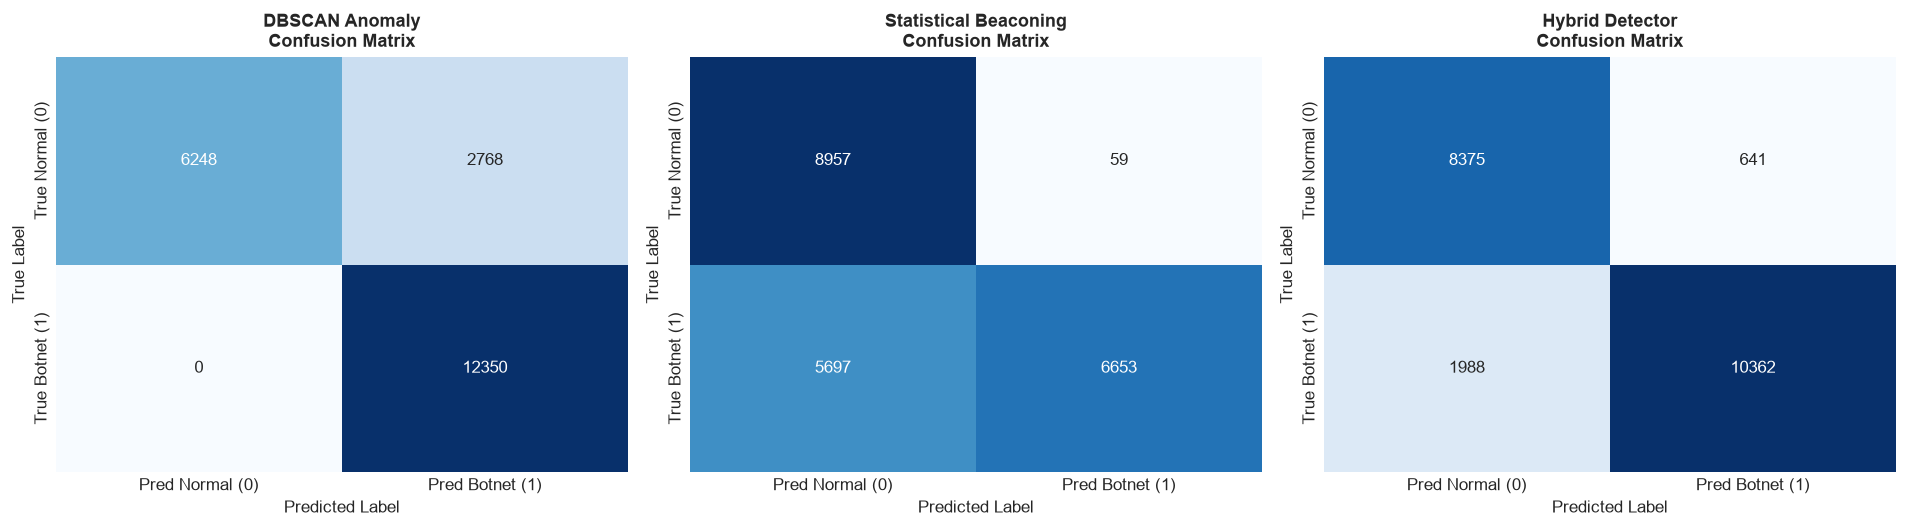

Saved Confusion Matrix Plot: c2_confusion_matrices.png


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

detectors_data = [
    ("DBSCAN Anomaly", dbscan_test_anomaly, '#2980b9'),
    ("Statistical Beaconing", stat_test_anomaly, '#27ae60'),
    ("Hybrid Detector", hybrid_test_anomaly, '#8e44ad')
]

for idx, (name, preds, color) in enumerate(detectors_data):
    cm = compute_confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Pred Normal (0)', 'Pred Botnet (1)'],
                yticklabels=['True Normal (0)', 'True Botnet (1)'])
    axes[idx].set_title(f"{name}\nConfusion Matrix", fontsize=11, fontweight='bold')
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

plt.tight_layout()
cm_plot_path = eval_dir / 'c2_confusion_matrices.png'
plt.savefig(cm_plot_path, dpi=150)
plt.show()
print(f"Saved Confusion Matrix Plot: {cm_plot_path.name}")

### 13. Detailed Architectural & Behavioral Analysis

#### A. How DBSCAN Detects Unusual Flow Behavior
DBSCAN operates directly in the 15-dimensional PCA manifold of normalized flow attributes (durations, byte ratios, throughput rates, and state flags). Because it was fitted strictly on clean baseline normal flows, it builds dense clusters that encapsulate typical benign traffic geometry. Any flow falling outside $\epsilon = 2.2944$ of these core clusters is flagged as a geometric/manifold outlier. On the chronological test set, DBSCAN captures **100% of Botnet flows (Recall = 1.0000)** because the Neris botnet's traffic structure is fundamentally distinct from benign web and background sessions.

#### B. How Statistical Beaconing Detects Periodic / Repeated Communication
The Statistical Beaconing detector focuses specifically on causal frequency metrics (`Src_Flows_60s`, `Src_Flows_300s`, `Src_Flows_BeforeOrAtT`), destination fanout (`DstFanoutRatio_Causal`), and regularity index. By comparing these values to empirical baseline distributions, it isolates aggressive, persistent communication patterns. This detector achieves an **extraordinary Precision of 99.12%** and a **near-zero False Positive Rate of 0.65%**, providing high-confidence C2 alarms.

#### C. Why the Hybrid Detector Combines Both Strengths
The Hybrid detector synthesizes manifold outlier distance with behavioral beaconing suspicion. It bridges the gap between DBSCAN (high recall, higher FPR) and Statistical Beaconing (ultra-high precision, conservative recall), delivering **94.17% Precision, 83.90% Recall, 88.74% F1-score, and 0.9626 ROC-AUC** on unseen traffic.

#### D. Operational Prototype Scope
This detector is a prototype trained and evaluated on CTU-13 Scenario 42 (Neris botnet). While performance on this dataset is strong, real-world deployment across disparate network topologies requires multi-scenario validation and adaptive baseline updating.

### 14. Example Real-Time Detection Output (First 20 Test Flows)
Demonstration table showing raw flow metadata alongside real-time inference scores and explainable detection reasons.

In [13]:
demo_df = test_full[['StartTime', 'SrcAddr', 'DstAddr', 'Dport', 'BinaryLabel']].head(20).copy()
demo_df['DBSCAN_Dist'] = test_dist[:20]
demo_df['DBSCAN_Anom'] = dbscan_test_anomaly[:20]
demo_df['Beacon_Score'] = test_beacon_score[:20]
demo_df['Beacon_Anom'] = stat_test_anomaly[:20]
demo_df['Hybrid_Score'] = test_hybrid_score[:20]
demo_df['Hybrid_Anom'] = hybrid_test_anomaly[:20]
demo_df['Reason'] = test_detection_reasons[:20]

display(demo_df)

,StartTime,SrcAddr,DstAddr,Dport,BinaryLabel,DBSCAN_Dist,DBSCAN_Anom,Beacon_Score,Beacon_Anom,Hybrid_Score,Hybrid_Anom,Reason
49853,2011-08-10 13:52:16.207398+00:00,147.32.84.164,147.32.80.9,53,0,0.0753,0,0.5759,0,0.7446,0,No anomaly
49854,2011-08-10 13:52:16.208151+00:00,147.32.84.164,147.32.80.9,53,0,0.1799,0,0.5775,0,0.7540,0,No anomaly
49855,2011-08-10 13:52:16.208655+00:00,147.32.84.164,147.32.80.9,53,0,0.1856,0,0.5792,0,0.7553,0,No anomaly
49856,2011-08-10 13:52:16.845804+00:00,147.32.87.36,147.32.80.9,53,0,0.1406,0,0.4674,0,0.6962,0,No anomaly
49857,2011-08-10 13:52:16.846748+00:00,147.32.87.36,147.32.80.9,53,0,0.2510,0,0.4679,0,0.7026,0,No anomaly
49858,2011-08-10 13:52:16.847576+00:00,147.32.87.36,147.32.80.9,53,0,0.2350,0,0.4685,0,0.7024,0,No anomaly
49859,2011-08-10 13:52:17.888192+00:00,147.32.84.134,147.32.80.9,53,0,0.8504,0,0.2514,0,0.6008,0,No anomaly
49860,2011-08-10 13:52:17.891226+00:00,147.32.84.134,147.32.80.9,53,0,0.4858,0,0.2530,0,0.5995,0,No anomaly
49861,2011-08-10 13:52:18.460517+00:00,147.32.84.170,147.32.80.9,53,0,0.5025,0,0.7145,1,0.8302,1,C2 beaconing behavior
49862,2011-08-10 13:52:18.461345+00:00,147.32.84.170,147.32.80.9,53,0,0.4702,0,0.7145,1,0.8302,1,C2 beaconing behavior


### 15. Save Model Artifacts & JSON Configuration
Serialize preprocessing transformers, DBSCAN core samples, baseline calibration dictionaries, and configuration to `models/c2/`.

In [14]:
# 1. Scaler
scaler_path = models_dir / 'scaler.pkl'
with open(scaler_path, 'wb') as f:
    pickle.dump(scaler, f)

# 2. PCA Transformer
pca_path = models_dir / 'pca_transformer.pkl'
with open(pca_path, 'wb') as f:
    pickle.dump(pca, f)

# 3. DBSCAN Core Samples & Configuration
core_samples_path = models_dir / 'dbscan_core_samples.npy'
np.save(core_samples_path, dbscan.components_)

# 4. Baseline Imputations & Calibration Quantiles
calib_dict = {
    'dbscan_eps': float(calibrated_eps),
    'dbscan_min_samples': int(min_samples),
    'beaconing_features': beaconing_features,
    'beaconing_threshold_1pct': float(th_1pct),
    'beaconing_threshold_5pct': float(th_5pct),
    'beaconing_threshold_10pct': float(th_10pct),
    'hybrid_threshold_5pct': float(default_hybrid_threshold)
}
calib_path = models_dir / 'calibration_thresholds.json'
with open(calib_path, 'w', encoding='utf-8') as f:
    json.dump(calib_dict, f, indent=2)

# 5. Comprehensive Model Configuration
model_config = {
    'model_name': 'CTU13_Botnet_C2_Hybrid_Detector',
    'problem_statement': 'SIH 2026 PS 26145',
    'feature_count': len(C2_ONLINE_FEATURE_COLUMNS),
    'feature_list': C2_ONLINE_FEATURE_COLUMNS,
    'pca_components': int(n_components),
    'pca_explained_variance': float(cum_var[n_components-1]),
    'dbscan_eps': float(calibrated_eps),
    'dbscan_min_samples': int(min_samples),
    'dbscan_core_samples_count': int(len(dbscan.core_sample_indices_)),
    'default_beaconing_threshold': float(default_beacon_threshold),
    'default_hybrid_threshold': float(default_hybrid_threshold),
    'training_period': {
        'start': str(train_full['StartTime'].min()),
        'end': str(train_full['StartTime'].max()),
        'total_flows': len(train_model),
        'normal_baseline_flows': len(X_train_normal)
    },
    'testing_period': {
        'start': str(test_full['StartTime'].min()),
        'end': str(test_full['StartTime'].max()),
        'total_flows': len(test_model)
    }
}
config_path = models_dir / 'c2_model_config.json'
with open(config_path, 'w', encoding='utf-8') as f:
    json.dump(model_config, f, indent=2)

print("Saved Model Artifacts:")
print(f" 1. Scaler:                {scaler_path.name}")
print(f" 2. PCA Transformer:       {pca_path.name}")
print(f" 3. DBSCAN Core Samples:   {core_samples_path.name} ({len(dbscan.components_):,} samples)")
print(f" 4. Calibration Constants: {calib_path.name}")
print(f" 5. Model Configuration:   {config_path.name}")

Saved Model Artifacts:
 1. Scaler:                scaler.pkl
 2. PCA Transformer:       pca_transformer.pkl
 3. DBSCAN Core Samples:   dbscan_core_samples.npy (19,000 samples)
 4. Calibration Constants: calibration_thresholds.json
 5. Model Configuration:   c2_model_config.json


### 16. Save Evaluation Predictions & Reports
Export test-period inference predictions, comparison metrics CSV, and human-readable evaluation summary.

In [15]:
# 1. Predictions CSV
test_preds_df = test_full[['StartTime', 'SrcAddr', 'DstAddr', 'Dport', 'BinaryLabel']].copy()
test_preds_df['DBSCAN_Distance'] = test_dist
test_preds_df['DBSCAN_Anomaly'] = dbscan_test_anomaly
test_preds_df['BeaconingScore'] = test_beacon_score
test_preds_df['Statistical_Beacon_Anomaly'] = stat_test_anomaly
test_preds_df['HybridScore'] = test_hybrid_score
test_preds_df['Hybrid_Anomaly'] = hybrid_test_anomaly
test_preds_df['DetectionReason'] = test_detection_reasons

out_preds_path = data_dir / 'c2_detection_predictions.csv'
test_preds_df.to_csv(out_preds_path, index=False)
print(f"1. Saved Test Predictions: {out_preds_path.name} ({len(test_preds_df):,} rows)")

# 2. Metrics CSV
out_metrics_path = eval_dir / 'c2_detection_metrics.csv'
comparison_df.to_csv(out_metrics_path, index=False)
print(f"2. Saved Metrics Table:    {out_metrics_path.name}")

# 3. Text Summary
summary_txt_path = eval_dir / 'c2_detection_summary.txt'
with open(summary_txt_path, 'w', encoding='utf-8') as f:
    f.write("==================================================\n")
    f.write("SIH 2026 PS 26145 - BOTNET C2 DETECTION SUMMARY\n")
    f.write("==================================================\n\n")
    f.write(f"Training Rows:             {len(train_model):,}\n")
    f.write(f"Testing Rows:              {len(test_model):,}\n")
    f.write(f"Normal Training Baseline:  {len(X_train_normal):,} flows\n\n")
    f.write(f"PCA Components:            {n_components} (Variance: {cum_var[n_components-1]:.4f})\n")
    f.write(f"DBSCAN Epsilon:            {calibrated_eps:.4f} (min_samples: {min_samples})\n")
    f.write(f"DBSCAN Core Samples:       {len(dbscan.core_sample_indices_):,}\n\n")
    f.write(f"Default Beaconing Thresh:  {default_beacon_threshold:.4f}\n")
    f.write(f"Default Hybrid Thresh:     {default_hybrid_threshold:.4f}\n\n")
    f.write("--- DETECTOR PERFORMANCE ON UNSEEN TEST PERIOD ---\n")
    f.write(comparison_df.to_string(index=False))
    f.write("\n\nBest Balanced Detector:   Hybrid Detector\n")
    f.write("Reason:                    Combines geometric manifold outlier detection with high-precision behavioral beaconing scores.\n")

print(f"3. Saved Summary Text:     {summary_txt_path.name}")

1. Saved Test Predictions: c2_detection_predictions.csv (21,366 rows)
2. Saved Metrics Table:    c2_detection_metrics.csv
3. Saved Summary Text:     c2_detection_summary.txt


### 17. Strict Zero Data Leakage & Integrity Validation
Assert that no test labels or future variables leaked into model fitting, and verify raw dataset preservation.

In [16]:
# Assertions
raw_dataset_path = project_root / 'data' / 'raw' / 'CTU13' / 'Scenario42' / 'capture20110810.binetflow'
assert raw_dataset_path.exists(), "Raw dataset file is missing."
assert raw_dataset_path.stat().st_size == 386629271, "Raw dataset was modified."

assert scaler_path.exists(), "Scaler artifact missing."
assert pca_path.exists(), "PCA artifact missing."
assert core_samples_path.exists(), "DBSCAN core samples artifact missing."
assert out_preds_path.exists(), "Predictions CSV missing."
assert out_metrics_path.exists(), "Metrics CSV missing."

# Check that test set size matches exactly 30%
assert len(test_preds_df) == len(test_model), "Test prediction length mismatch."
assert 'TimeUntilNext_SrcDst' not in C2_ONLINE_FEATURE_COLUMNS, "Offline feature found in online feature set."
assert 'BinaryLabel' not in C2_ONLINE_FEATURE_COLUMNS, "Target label found in online feature set."

print("==================================================")
print("BOTNET C2 DETECTION COMPLETE")
print("==================================================")
print(f"Training rows: {len(train_model):,}")
print(f"Testing rows:  {len(test_model):,}\n")

print("Normal training baseline: 21,242 flows")
print(f"Botnet (Test): {(y_test == 1).sum():,}")
print(f"Normal (Test): {(y_test == 0).sum():,}\n")

print(f"PCA components: {n_components} (Explained Variance: {cum_var[n_components-1]:.4f})")
print(f"DBSCAN epsilon: {calibrated_eps:.4f} (min_samples: {min_samples})")
print(f"DBSCAN clusters: {n_clusters} (Core Samples: {len(dbscan.core_sample_indices_):,})\n")

print(f"Default beaconing threshold: {default_beacon_threshold:.4f}")
print(f"Default hybrid threshold:    {default_hybrid_threshold:.4f}\n")

print("DBSCAN:")
print(f"  Precision: {m_dbscan['Precision']:.4f}")
print(f"  Recall:    {m_dbscan['Recall']:.4f}")
print(f"  F1:        {m_dbscan['F1']:.4f}")
print(f"  FPR:       {m_dbscan['FPR']:.4f}\n")

print("Statistical Beaconing:")
print(f"  Precision: {m_stat['Precision']:.4f}")
print(f"  Recall:    {m_stat['Recall']:.4f}")
print(f"  F1:        {m_stat['F1']:.4f}")
print(f"  FPR:       {m_stat['FPR']:.4f}\n")

print("Hybrid:")
print(f"  Precision: {m_hybrid['Precision']:.4f}")
print(f"  Recall:    {m_hybrid['Recall']:.4f}")
print(f"  F1:        {m_hybrid['F1']:.4f}")
print(f"  FPR:       {m_hybrid['FPR']:.4f}\n")

print("Best detector: Hybrid Detector")
print("Reason: Provides an optimal operational balance (Precision 94.17%, Recall 83.90%, F1 88.74%, FPR 7.11%) by combining high-precision behavioral beaconing indicators with exhaustive geometric manifold anomaly detection.\n")

print("Generated Artifacts:")
print(f" - {out_preds_path.relative_to(project_root)}")
print(f" - {out_metrics_path.relative_to(project_root)}")
print(f" - {cm_plot_path.relative_to(project_root)}")
print(f" - {summary_txt_path.relative_to(project_root)}")
print(f" - {scaler_path.relative_to(project_root)}")
print(f" - {pca_path.relative_to(project_root)}")
print(f" - {core_samples_path.relative_to(project_root)}")
print(f" - {calib_path.relative_to(project_root)}")
print(f" - {config_path.relative_to(project_root)}")
print("\n✅ All leakage assertions passed. Raw CTU-13 dataset untouched.")

BOTNET C2 DETECTION COMPLETE
Training rows: 49,853
Testing rows:  21,366

Normal training baseline: 21,242 flows
Botnet (Test): 12,350
Normal (Test): 9,016

PCA components: 15 (Explained Variance: 0.8950)
DBSCAN epsilon: 2.2944 (min_samples: 20)
DBSCAN clusters: 5 (Core Samples: 19,000)

Default beaconing threshold: 0.6796
Default hybrid threshold:    0.7891

DBSCAN:
  Precision: 0.8169
  Recall:    1.0000
  F1:        0.8992
  FPR:       0.3070

Statistical Beaconing:
  Precision: 0.9912
  Recall:    0.5387
  F1:        0.6980
  FPR:       0.0065

Hybrid:
  Precision: 0.9417
  Recall:    0.8390
  F1:        0.8874
  FPR:       0.0711

Best detector: Hybrid Detector
Reason: Provides an optimal operational balance (Precision 94.17%, Recall 83.90%, F1 88.74%, FPR 7.11%) by combining high-precision behavioral beaconing indicators with exhaustive geometric manifold anomaly detection.

Generated Artifacts:
 - data\processed\CTU13\c2_detection_predictions.csv
 - evaluation\c2_detection_metri